# Zomato Bangalore: Pricing & Rating Analysis

**Questions**
1. Does a higher price mean a better rating?
2. Do online ordering and table booking go with higher ratings?
3. Does the listing type (Dining, Cafes, Buffet, Other) matter?
4. How much can we trust the ratings, and which restaurants are genuinely good value?

> The dataset has 148 rows and 7 columns (no location or cuisine), so the analysis is built around price, rating, votes, services and listing type. Samples are small, so group differences come with bootstrap confidence intervals.

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
from clean_data import clean, RAW
from eda import run
pd.set_option('display.max_columns', 30)
raw = pd.read_csv(RAW)
print(raw.shape)
raw.head()

(148, 7)


,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


## 1. Inspect
Ratings are text (`4.1/5`, once `3.8 /5`), names are sometimes ALL CAPS, and a few restaurants appear under more than one listing type.

In [2]:
raw['rate'].value_counts().sort_index().head(25)

rate
2.6/5      1
2.8/5      2
2.9/5      7
3.0/5      2
3.1/5      7
3.2/5      7
3.3/5     14
3.4/5     12
3.5/5      6
3.6/5     11
3.7/5     15
3.8 /5     1
3.8/5     19
3.9/5     10
4.0/5     10
4.1/5     11
4.2/5      8
4.3/5      1
4.4/5      2
4.6/5      2
Name: count, dtype: int64

In [3]:
raw[raw.duplicated('name', keep=False)].sort_values('name')

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
25,CAFE NOVA,No,No,3.2/5,11,600,Cafes
104,CAFE NOVA,No,No,3.2/5,11,600,Dining
7,Onesta,Yes,Yes,4.6/5,2556,600,Cafes
44,Onesta,Yes,Yes,4.6/5,2556,600,other
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
14,San Churro Cafe,Yes,No,3.8/5,918,800,Cafes


## 2. Clean
See `src/clean_data.py`. Key steps: parse ratings, normalise names, merge multi-listed restaurants into one row (keeping a separate listings table), derive price bands, and compute a **vote-adjusted rating** because many ratings rest on very few votes.

In [4]:
rest, listings, log = clean(raw)
print(json.dumps(log, indent=2))
rest.head()

{
  "raw_rows": 148,
  "raw_columns": [
    "name",
    "online_order",
    "book_table",
    "rate",
    "votes",
    "approx_cost(for two people)",
    "listed_in(type)"
  ],
  "rating_format_fixed": 1,
  "names_recased": 2,
  "rows_with_missing_core_fields": 0,
  "listing_rows": 148,
  "restaurants": 145,
  "multi_listed_restaurants": 3,
  "low_confidence_ratings": 75,
  "zero_vote_restaurants": 33,
  "bayesian_prior_mean": 3.628
}


,restaurant_id,name,online_order,book_table,rating,votes,cost_for_two,price_band,bayes_rating,reliable_rating,listed_types
0,1,Jalsa,True,True,4.1,775,800,601-800,4.07,True,Buffet
1,2,Spice Elephant,True,False,4.1,787,800,601-800,4.07,True,Buffet
2,3,San Churro Cafe,True,False,3.8,918,800,601-800,3.79,True,Buffet; Cafes
3,4,Addhuri Udupi Bhojana,False,False,3.7,88,300,201-400,3.67,True,Buffet
4,5,Grand Village,False,False,3.8,166,600,401-600,3.76,True,Buffet


## 3. Rating reliability
Half the restaurants have fewer than 50 votes, and some have a rating with 0 votes.

In [5]:
rest['votes'].describe()

count     145.000000
mean      246.255172
std       629.272086
min         0.000000
25%         6.000000
50%        42.000000
75%       201.000000
max      4884.000000
Name: votes, dtype: float64

In [6]:
rest.groupby('reliable_rating')[['rating', 'votes', 'cost_for_two']].agg(['count', 'mean']).round(2)

rating       votes         cost_for_two        
                 count  mean count    mean        count    mean
reliable_rating                                                
False               75  3.45    75   11.96           75  317.33
True                70  3.82    70  497.29           70  515.71

## 4. Analysis and insights
`run()` draws the charts and returns the findings as text.

In [7]:
notes = run(rest, listings)
for i, n in enumerate(notes, 1):
    print(f'{i}. {n}\n')

1. The dataset has **145** restaurants. Median rating is **3.7**, median cost for two **₹400**, and median votes only **42**: votes are heavily right-skewed (max 4,884).

2. **75 of 145 restaurants (52%) have fewer than 50 votes**, and **33** carry a rating with zero votes. Those ratings are weak evidence, so conclusions below for price and online ordering are re-checked on the reliable subset.

3. Price and rating are positively related (Spearman ρ = **0.31**, p = 0.000178) across all restaurants, but ρ = **0.17** (p = 0.171, n=70) among those with 50+ votes, and the link is not statistically clear once low-vote restaurants are excluded. Average rating runs from 3.51 in the ₹100-200 band to 3.82 at 601-800; the top band has only 5 restaurants, so its interval is wide.

4. Online ordering: average rating **3.85** with (n=56) vs **3.49** without (n=89); difference +0.36, 95% CI [+0.24, +0.47], Mann-Whitney p = 2.16e-08; the interval excludes zero. Among restaurants with 50+ votes (n=70)

### Charts

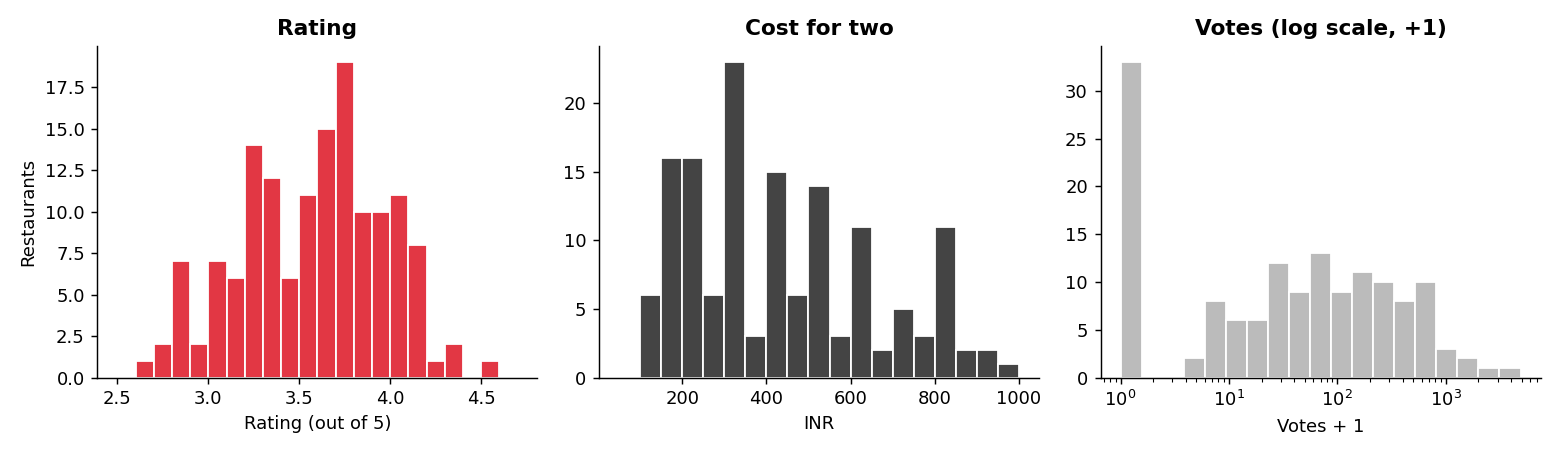

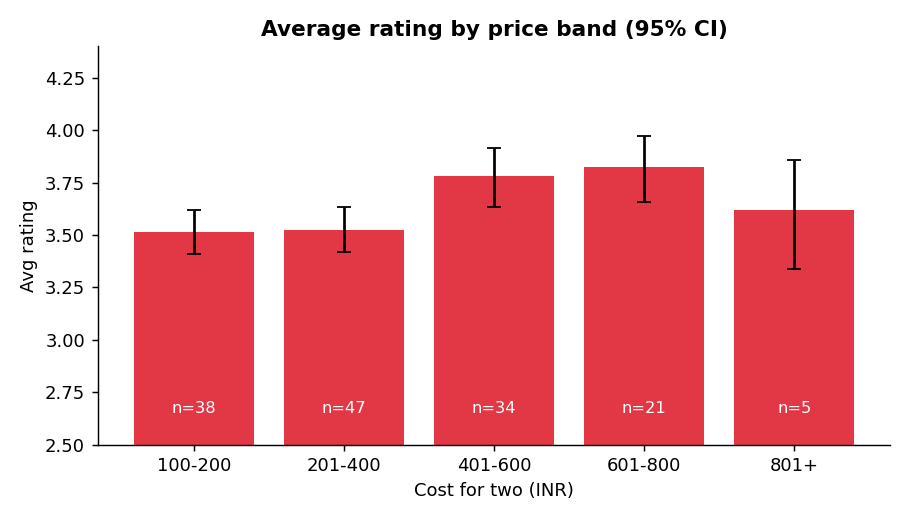

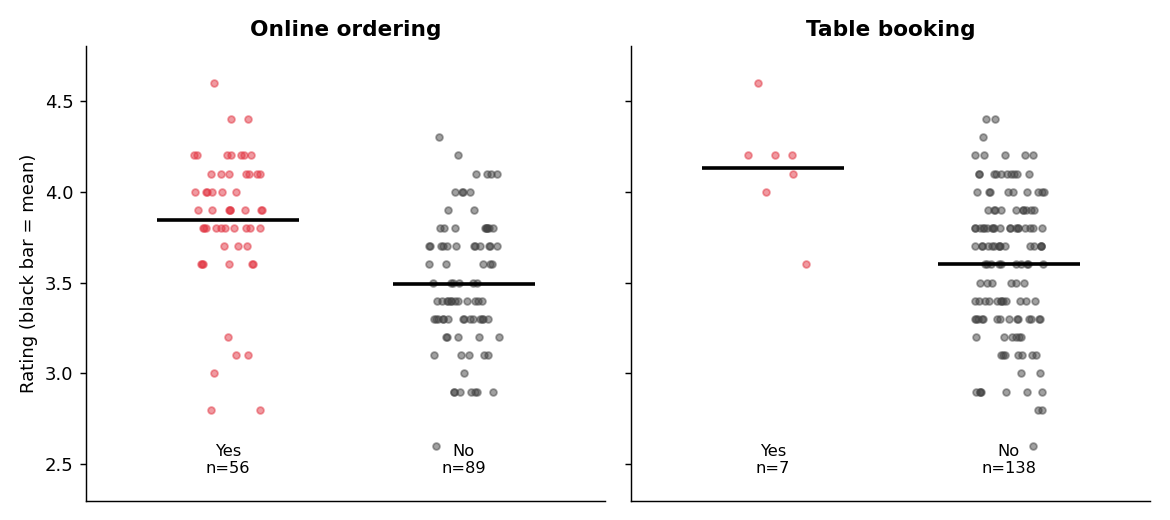

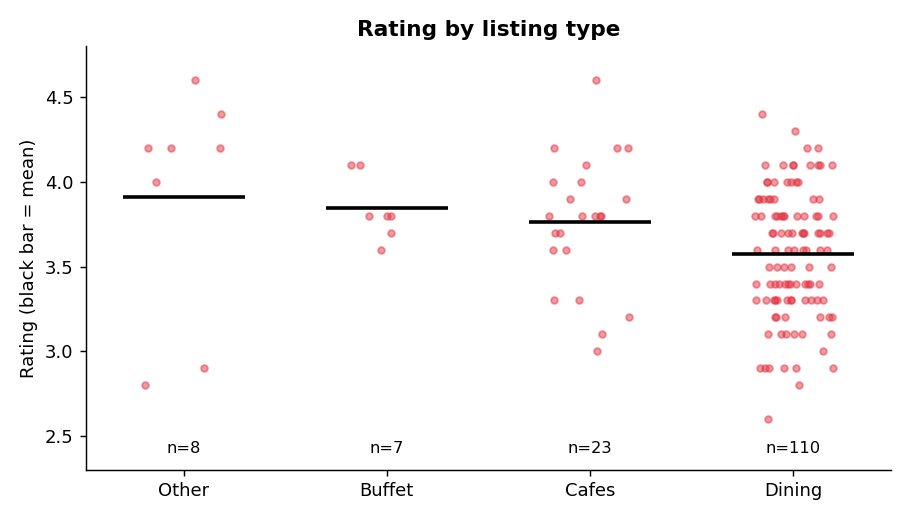

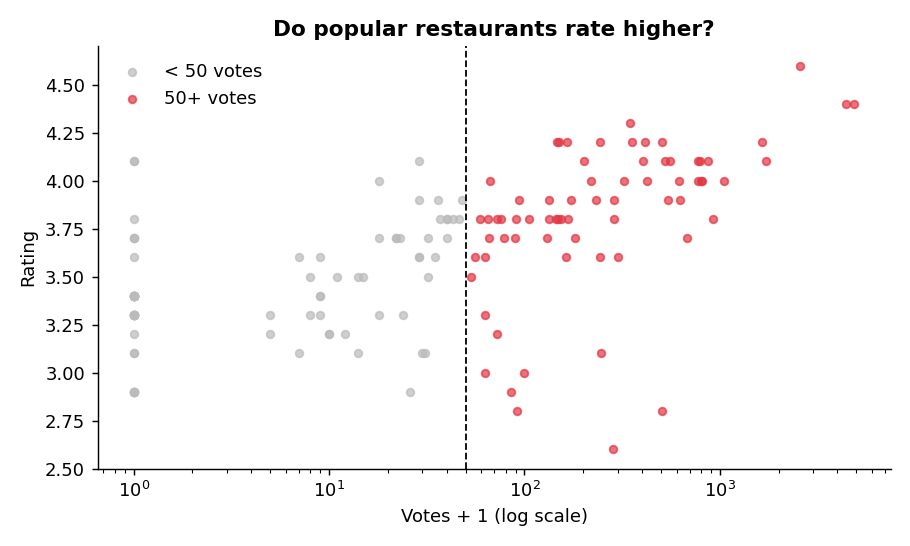

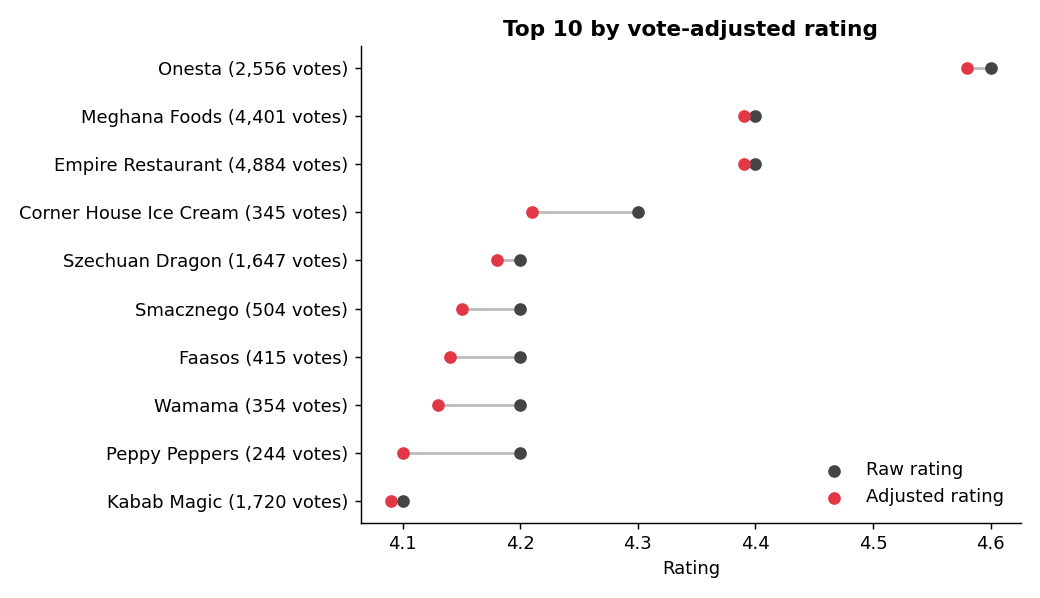

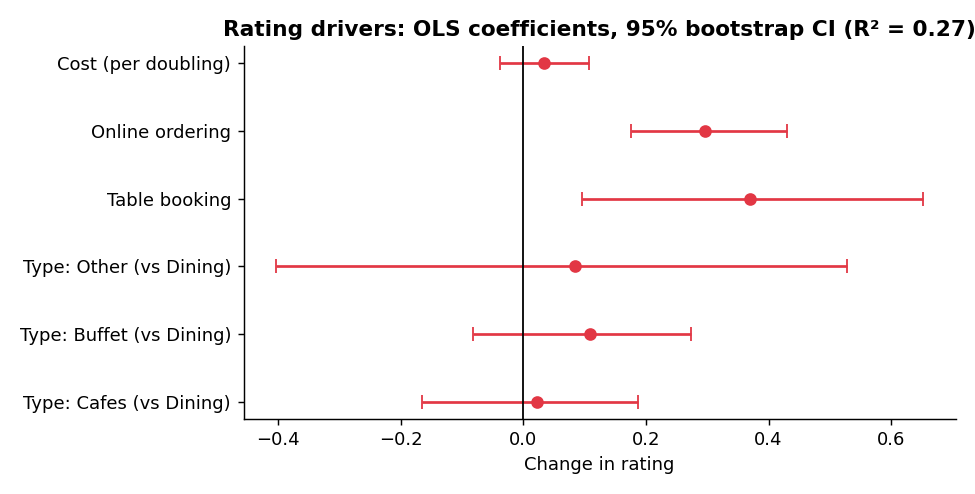

In [8]:
for f in ['01_distributions','02_rating_by_price_band','03_services_vs_rating','04_rating_by_listing_type','05_votes_vs_rating','06_adjusted_ranking','07_regression_coefficients']:
    display(Image(f'../reports/figures/{f}.png'))

## 5. Takeaways
- **Treat ratings with votes in mind.** About half of the ratings rest on fewer than 50 votes; use the vote-adjusted rating or filter to 50+ votes.
- **Online ordering and table booking go with higher ratings**, but the online-ordering gap shrinks and loses significance among well-reviewed restaurants, and the table-booking group is tiny.
- **Price is only loosely tied to rating** once thinly reviewed places are excluded.
- **Caveats:** 145 restaurants, no location or cuisine data, all results are associations.